# Exercise 2: reduce before copying to host

## Question

Can we compute the Power Doppler reduction on the GPU and transfer only the reduced result to the host?

This notebook reads the short NumPy and CuPy Nsight Systems captures from the Colab T4, summarizes the device-to-host (D2H) copies, and checks that both paths produce matching Power Doppler maps. The capture files are local artifacts under `artifacts/`; they are ignored by Git because profiler traces and arrays are generated data.

**Observed answer:** yes. Across the five profiled ensemble calls per mode, the NumPy path transferred 80.641 MB D2H, while CuPy transferred 1.260 MB. The map payload is about 64× smaller after reduction. This confirms the transfer-path change; it does not isolate which part of CuPy's overall performance difference comes from beamforming versus reduction.


## What differs between the paths

Both modes beamform the same 32-frame IQ ensemble on the GPU. In NumPy mode, the beamformed complex64 ensemble is copied to host memory and Power Doppler reduction happens on the CPU. In CuPy mode, `sum(abs(beamformed) ** 2, axis=-1)` runs on the GPU; the final float32 map and a small scalar summary are copied to the host.

For the 251 × 251 grid, there are 63,001 pixels:

| Output transferred after beamforming | Shape and dtype | Bytes per ensemble |
|---|---|---:|
| Full beamformed ensemble (NumPy path) | 63,001 × 32 complex64 | 16,128,256 (16.128 MB) |
| Reduced Power Doppler map (CuPy path) | 63,001 float32 | 252,004 (0.252 MB) |

The expected map-to-ensemble payload ratio is 64×. CuPy also returns the scalar summary, so the trace contains a second, tiny D2H copy for each ensemble.


## Capture conditions

- Colab GPU: NVIDIA Tesla T4, compute capability 7.5
- Nsight Systems CLI: 2025.3.1.0
- Repository revision used by both runs: `cd0daebc1fd6e76ed0f84f24b815c1c096a0d687`
- Dataset: PyMUST rotating-disk Doppler phantom
- Grid: 251 × 251; frames per ensemble: 32
- Each command used 2 warmups and 3 measured calls. The trace therefore includes 5 calls per mode.
- The runs used identical command settings and revision. The report JSON files preserve the exact command and runtime provenance.

The profiler traced CUDA, NVTX, and OS runtime activity, with CPU sampling and context-switch collection disabled. These short traces are for locating transfers and kernels. Use an unprofiled benchmark for end-to-end latency comparisons.

The analysis cells were executed locally on macOS in the `realtime-beamforming-ex2` Conda kernel. The T4 listed in the report output is the capture hardware from Colab; the local analysis run did not use a GPU.


## Commands used on the Colab T4

Run from `/content/realtime-beamforming-lab` after the project and GPU dependencies are installed. Nsight Systems was already available in this runtime (`nsys --version` reported 2025.3.1.0).

The two profiling commands were:

```bash
nsys profile --trace=cuda,nvtx,osrt --sample=none --cpuctxsw=none \
  --output=artifacts/exercise2-pymust-numpy \
  beamform-lab benchmark --dataset pymust --mode numpy --runs 3 --warmup 2 \
  --batch-size 32 --grid-size 251 \
  --output results/exercise2-pymust-numpy.json \
  --save-power artifacts/exercise2-pymust-numpy-power.npy

nsys profile --trace=cuda,nvtx,osrt --sample=none --cpuctxsw=none \
  --output=artifacts/exercise2-pymust-cupy \
  beamform-lab benchmark --dataset pymust --mode cupy --runs 3 --warmup 2 \
  --batch-size 32 --grid-size 251 \
  --output results/exercise2-pymust-cupy.json \
  --save-power artifacts/exercise2-pymust-cupy-power.npy
```

The transfer summaries were generated with:

```bash
nsys stats --report cuda_gpu_mem_size_sum,cuda_gpu_mem_time_sum \
  artifacts/exercise2-pymust-numpy.nsys-rep \
  > results/exercise2-pymust-numpy-transfer-stats.txt

nsys stats --report cuda_gpu_mem_size_sum,cuda_gpu_mem_time_sum \
  artifacts/exercise2-pymust-cupy.nsys-rep \
  > results/exercise2-pymust-cupy-transfer-stats.txt
```

`nsys stats` creates or uses the companion `.sqlite` export. This notebook reads those SQLite exports directly, so the aggregate transfer table can be regenerated without parsing terminal text.


## Check that the reports are a matched pair

The JSON report records the run command, revision, device, and workload dimensions. This cell checks that the two reports agree on those comparison conditions.


In [1]:
import json
import platform
import sys
from pathlib import Path

import numpy as np

print("Local analysis kernel:", sys.executable)
print("Python:", platform.python_version())

repo_candidates = [Path("/content/realtime-beamforming-lab"), Path.cwd(), *Path.cwd().resolve().parents]
REPO = next((path for path in repo_candidates if (path / "pyproject.toml").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Could not locate the repository root; open this notebook from the project checkout.")
ARTIFACTS = REPO / "artifacts"
RESULTS = REPO / "results"

reports = {
    mode: json.loads((RESULTS / f"exercise2-pymust-{mode}.json").read_text())
    for mode in ("numpy", "cupy")
}

numpy_report, cupy_report = reports["numpy"], reports["cupy"]
assert numpy_report["runtime_provenance"]["git_revision"] == cupy_report["runtime_provenance"]["git_revision"]
assert numpy_report["runtime_provenance"]["gpu"] == cupy_report["runtime_provenance"]["gpu"]
assert numpy_report["iq_shape_elements_samples_frames"] == cupy_report["iq_shape_elements_samples_frames"]
assert numpy_report["scan_grid_points"] == cupy_report["scan_grid_points"]
assert numpy_report["batch_size_frames"] == cupy_report["batch_size_frames"]

print("GPU:", numpy_report["runtime_provenance"]["gpu"]["name"])
print("Revision:", numpy_report["runtime_provenance"]["git_revision"])
print("IQ shape (elements, samples, frames):", numpy_report["iq_shape_elements_samples_frames"])
print("Grid points / frames per ensemble:", numpy_report["scan_grid_points"], "/", numpy_report["frames_per_ensemble"])
print("Warmups / measured calls:", numpy_report["warmup_runs"], "/", numpy_report["measurement_runs"])


Local analysis kernel: /Users/vickgidwani/miniconda3/envs/realtime-beamforming-ex2/bin/python
Python: 3.13.18
GPU: Tesla T4
Revision: cd0daebc1fd6e76ed0f84f24b815c1c096a0d687
IQ shape (elements, samples, frames): [128, 334, 32]
Grid points / frames per ensemble: 63001 / 32
Warmups / measured calls: 2 / 3


## The transfer counts and times in the trace

The SQLite export exposes individual CUDA memcpy activities. We sum D2H bytes and elapsed GPU copy time across the whole trace. These totals include both warmups and all measured calls, not just the three measured calls.

The captured totals were:

| Path | D2H events | Total D2H bytes | Summed D2H time | D2H payload breakdown per ensemble |
|---|---:|---:|---:|---|
| NumPy | 5 | 80,641,280 (80.641 MB) | 19.530 ms | one 16,128,256-byte complex64 ensemble |
| CuPy | 10 | 1,260,040 (1.260 MB) | 0.118 ms | one 252,004-byte float32 map plus one 4-byte scalar |

The event sizes show five full-ensemble copies for NumPy and, for CuPy, five map copies plus five scalar copies.


In [2]:
import sqlite3
import pandas as pd
from IPython.display import display


def cuda_copy_summary(mode):
    trace_db = ARTIFACTS / f"exercise2-pymust-{mode}.sqlite"
    if not trace_db.is_file():
        raise FileNotFoundError(
            f"Missing {trace_db}. Re-run `nsys stats` on the matching .nsys-rep file to export it."
        )
    with sqlite3.connect(trace_db) as connection:
        rows = connection.execute(
            """
            SELECT operation.label, COUNT(*), SUM(memcpy.bytes), SUM(memcpy.end - memcpy.start)
            FROM CUPTI_ACTIVITY_KIND_MEMCPY AS memcpy
            JOIN ENUM_CUDA_MEMCPY_OPER AS operation ON operation.id = memcpy.copyKind
            WHERE memcpy.copyKind IN (1, 2)
            GROUP BY operation.label
            ORDER BY operation.label
            """
        ).fetchall()
    return {
        label: {"copies": count, "bytes": total_bytes, "time_ns": total_ns}
        for label, count, total_bytes, total_ns in rows
    }

copy_summaries = {mode: cuda_copy_summary(mode) for mode in ("numpy", "cupy")}
summary_rows = []
for mode, directions in copy_summaries.items():
    for direction in ("Device-to-Host", "Host-to-Device"):
        item = directions.get(direction, {"copies": 0, "bytes": 0, "time_ns": 0})
        summary_rows.append({
            "Path": mode.capitalize(),
            "Direction": direction,
            "Copies": item["copies"],
            "Bytes (MB)": item["bytes"] / 1_000_000,
            "Copy time (ms)": item["time_ns"] / 1_000_000,
        })
transfer_summary = pd.DataFrame(summary_rows)
display(transfer_summary.round({"Bytes (MB)": 3, "Copy time (ms)": 3}))


,Path,Direction,Copies,Bytes (MB),Copy time (ms)
0,Numpy,Device-to-Host,5,80.641,19.530
1,Numpy,Host-to-Device,20,59.770,12.459
2,Cupy,Device-to-Host,10,1.260,0.118
3,Cupy,Host-to-Device,8,55.732,4.626


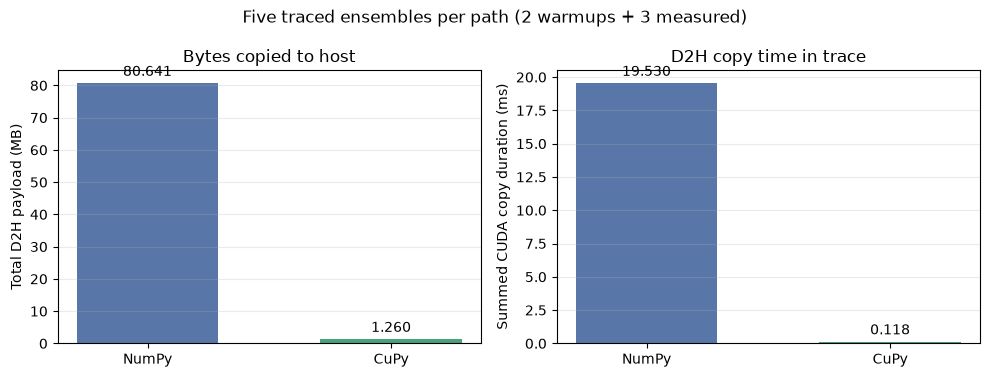

In [3]:
import matplotlib.pyplot as plt

modes = ("numpy", "cupy")
labels = ("NumPy", "CuPy")
d2h = [copy_summaries[mode]["Device-to-Host"] for mode in modes]
values_mb = [item["bytes"] / 1_000_000 for item in d2h]
values_ms = [item["time_ns"] / 1_000_000 for item in d2h]
colors = ("#5877a8", "#48a27a")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for axis, values, ylabel, title in (
    (axes[0], values_mb, "Total D2H payload (MB)", "Bytes copied to host"),
    (axes[1], values_ms, "Summed CUDA copy duration (ms)", "D2H copy time in trace"),
):
    bars = axis.bar(labels, values, color=colors, width=0.58)
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.25)
    axis.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=3)
fig.suptitle("Five traced ensembles per path (2 warmups + 3 measured)")
fig.tight_layout()
plt.show()


### Reading this comparison

NumPy produced five full-ensemble D2H copies. CuPy produced ten smaller D2H copies: one reduced map and one scalar summary per ensemble. The scalar is also a host transfer, but tiny next to the map. Across these five calls, the CuPy D2H payload is approximately 64× smaller. The summed copy durations are profiler observations for these events, not a standalone application speedup claim.


## Numerical check: compare the Power Doppler maps

The saved maps are both 251 × 251 float32 arrays. This checks normalized L2 error, maximum absolute difference relative to their shared peak, and correlation. If the `.npy` files are absent in a fresh checkout, run the two benchmark commands above to regenerate them.


In [4]:
numpy_map_path = ARTIFACTS / "exercise2-pymust-numpy-power.npy"
cupy_map_path = ARTIFACTS / "exercise2-pymust-cupy-power.npy"
if not numpy_map_path.is_file() or not cupy_map_path.is_file():
    raise FileNotFoundError("Power Doppler map artifacts are missing; run the paired benchmark commands first.")

numpy_map = np.load(numpy_map_path)
cupy_map = np.load(cupy_map_path)
assert numpy_map.shape == cupy_map.shape == (251, 251)

shared_peak = max(float(np.max(numpy_map)), float(np.max(cupy_map)))
difference = numpy_map.astype(np.float64) - cupy_map.astype(np.float64)
map_metrics = {
    "Normalized L2 error": float(np.linalg.norm(difference) / np.linalg.norm(numpy_map)),
    "Maximum absolute difference / shared peak": float(np.max(np.abs(difference)) / shared_peak),
    "Correlation": float(np.corrcoef(numpy_map.ravel(), cupy_map.ravel())[0, 1]),
}
for name, value in map_metrics.items():
    print(f"{name}: {value:.10g}")


Normalized L2 error: 5.874227441e-08
Maximum absolute difference / shared peak: 1.404988397e-07
Correlation: 1


## What the CUDA timeline shows

These screenshots are from the saved Nsight Systems reports. Each trace contains five ensemble calls: two warmups followed by three measured calls. The Events View lists individual copies, and the Description pane gives the selected copy size, duration, and memory kinds.


### NumPy: copy the full beamformed ensemble to the host

![Nsight Systems NumPy timeline showing beamforming and a full-ensemble DtoH copy](../results/exercise2-nsys-numpy-d2h.png)

Each `beamformKernel` call is followed by a 16,128,256-byte Device-to-Host copy of the beamformed ensemble to pageable host memory (about 16.1 MB). Five such copies appear in the trace. The selected copy took 3.967 ms. The CPU performs the Power Doppler reduction after this transfer.


### CuPy: reduce on the GPU, then copy the map to the host

![Nsight Systems CuPy timeline showing GPU Power Doppler reduction and reduced DtoH copies](../results/exercise2-nsys-cupy-d2h.png)

The kernel tracks show the beamforming and Power Doppler work on the GPU: magnitude, power, and the sum across frames. The selected Device-to-Host copy returns the 251 × 251 float32 Power Doppler map (252,004 bytes); it took 21.376 µs in this event. The adjacent 4-byte DtoH events are the scalar summary. Five map-and-scalar pairs appear across the five calls.


## Extension: isolate the reduction timing

Across the five CuPy trace calls, the median active GPU kernel times for magnitude, power, and summing across frames add up to about 0.89 ms. The 21.4 µs event selected in the screenshot is the separate map transfer. The current benchmark does not time the NumPy reduction by itself.

The `benchmark-reduction` command creates one beamformed complex64 ensemble on the T4 and feeds the same values to both reducers. It reports compute-only timings with the input already resident on each processor, plus post-beamforming timings that include each path's required transfer.

Run an unprofiled timing comparison:

```bash
beamform-lab benchmark-reduction --runs 20 --warmup 5 --batch-repeats 5 \
  --output results/exercise2-reduction.json
```

For a short Nsight Systems capture with stage labels:

```bash
nsys profile --trace=cuda,nvtx,osrt --sample=none --cpuctxsw=none \
  --output=artifacts/exercise2-reduction \
  beamform-lab benchmark-reduction --runs 3 --warmup 2 --batch-repeats 1 --nvtx
```

**NVTX ranges** are named spans around code stages. Nsight Systems shows them on the CPU timeline and associates GPU kernels launched inside them. The benchmark labels setup, CPU/GPU reduction, and each post-beamforming transfer-and-reduce path. Use the unprofiled JSON for timing comparisons; the trace is for understanding where work occurs. Perfetto is not needed.


## Takeaway

For this workload, reducing the 32-frame beamformed ensemble to a Power Doppler map on the GPU changes the D2H payload from about 16.1 MB to about 0.252 MB per ensemble, plus a tiny scalar. The captured traces show this change directly, and the resulting maps agree closely (normalized L2 error about 5.87 × 10⁻⁸).

This answers the exercise's data-movement question. The transfer trace alone does not show whether the practical speed difference comes from beamforming, reduction, or their interaction. The extension above prepares a focused CPU/GPU reducer comparison, including the post-beamforming transfer paths; its timing results are pending a T4 run.
